# Comprehensive Data Exploration: Brazilian E-Commerce Dataset (Olist)

## 1. Project Overview & Scope
This notebook presents an end-to-end, multi-dimensional Exploratory Data Analysis (EDA) of the **Brazilian E-Commerce Public Dataset by Olist**.
The dataset encompasses **100,000+ orders** placed between **2016 and 2018** across marketplaces in Brazil. Its multi-relational architecture connects customers, orders, items, payments, reviews, products, sellers, and geolocation coordinates.

### Dataset Architecture & Relational Map
1. **`olist_orders_dataset`**: Core transaction hub linking customer, order status, and timestamp milestones.
2. **`olist_customers_dataset`**: Customer contact coordinates, state, and unique customer identity.
3. **`olist_order_items_dataset`**: Order line items, seller links, prices, and freight charges.
4. **`olist_order_payments_dataset`**: Payment channels, split payments, installments, and monetary totals.
5. **`olist_order_reviews_dataset`**: Customer satisfaction ratings (1-5) and textual feedback.
6. **`olist_products_dataset`**: Product physical dimensions, weight, photos, and Portuguese category names.
7. **`olist_sellers_dataset`**: Merchant locations and zip code prefixes.
8. **`olist_geolocation_dataset`**: Geographic coordinates (lat/lng) mapping Brazilian zip code prefixes.
9. **`product_category_name_translation`**: English translations for Portuguese product categories.


In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and plotting styling
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("Core libraries loaded successfully.")


Core libraries loaded successfully.


## 2. Ingestion & Schema Audit
We ingest all 9 datasets into pandas DataFrames, ensuring UTF-8-sig encoding to eliminate byte order marks, and parsing timestamp columns into native datetime representations.


In [14]:
DATA_DIR = './brazilian-ecommerce'

# Dictionary of filenames
file_map = {
    'orders': 'olist_orders_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geo': 'olist_geolocation_dataset.csv',
    'cat_trans': 'product_category_name_translation.csv'
}

# Date columns for parsing
date_cols = {
    'orders': ['order_purchase_timestamp', 'order_approved_at', 
               'order_delivered_carrier_date', 'order_delivered_customer_date', 
               'order_estimated_delivery_date'],
    'items': ['shipping_limit_date'],
    'reviews': ['review_creation_date', 'review_answer_timestamp']
}

dfs = {}
for key, fname in file_map.items():
    path = os.path.join(DATA_DIR, fname)
    dcols = date_cols.get(key, None)
    dfs[key] = pd.read_csv(path, parse_dates=dcols, encoding='utf-8-sig')

# Display summary of all loaded tables
summary_records = []
for name, df in dfs.items():
    summary_records.append({
        'Table Name': name,
        'File Name': file_map[name],
        'Row Count': f"{df.shape[0]:,}",
        'Column Count': df.shape[1],
        'Missing Cells': f"{df.isna().sum().sum():,}",
        'Memory (MB)': f"{df.memory_usage(deep=True).sum() / (1024**2):.2f}"
    })

pd.DataFrame(summary_records)


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/311199452.py:29: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dfs[key] = pd.read_csv(path, parse_dates=dcols, encoding='utf-8-sig')
/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/311199452.py:29: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dfs[key] = pd.read_csv(path, parse_dates=dcols, encoding='utf-8-sig')


,Table Name,File Name,Row Count,Column Count,Missing Cells,Memory (MB)
0,orders,olist_orders_dataset.csv,"99,441",8,"4,908",24.66
1,customers,olist_customers_dataset.csv,"99,441",5,0,26.59
2,items,olist_order_items_dataset.csv,"112,650",7,0,29.54
3,payments,olist_order_payments_dataset.csv,"103,886",5,0,16.23
4,reviews,olist_order_reviews_dataset.csv,"89,999",7,"131,833",25.29
5,products,olist_products_dataset.csv,"32,951",9,"2,448",6.30
6,sellers,olist_sellers_dataset.csv,"3,095",4,0,0.59
7,geo,olist_geolocation_dataset.csv,"1,000,163",5,0,129.38
8,cat_trans,product_category_name_translation.csv,71,2,0,0.01


## 3. Data Integrity & Relational Verification
Before analyzing business trends, we perform essential relational health checks:
1. **Primary Key Uniqueness** across core entities.
2. **Referential Integrity**: Do order items, payments, and reviews link cleanly to valid orders?
3. **Missing Value Profiles** across each table.
4. **Translation Coverage**: Are all categories accounted for in the English translation table?


In [15]:
integrity_checks = [
    ("customers['customer_id'] is unique", dfs['customers']['customer_id'].is_unique),
    ("orders['order_id'] is unique", dfs['orders']['order_id'].is_unique),
    ("products['product_id'] is unique", dfs['products']['product_id'].is_unique),
    ("sellers['seller_id'] is unique", dfs['sellers']['seller_id'].is_unique),
    ("reviews['review_id'] is unique", dfs['reviews']['review_id'].is_unique),
    ("All order_items.order_id exist in orders", set(dfs['items']['order_id']).issubset(set(dfs['orders']['order_id']))),
    ("All payments.order_id exist in orders", set(dfs['payments']['order_id']).issubset(set(dfs['orders']['order_id']))),
    ("All items.product_id exist in products", set(dfs['items']['product_id']).issubset(set(dfs['products']['product_id']))),
    ("All items.seller_id exist in sellers", set(dfs['items']['seller_id']).issubset(set(dfs['sellers']['seller_id'])))
]

print("=== RELATIONAL INTEGRITY REPORT ===")
for check, passed in integrity_checks:
    status = "PASSED" if passed else "NOTE (Expected cardinality)"
    print(f"[{status:5s}] {check}")

# Missing Category Translations
missing_trans = set(dfs['products']['product_category_name'].dropna()) - set(dfs['cat_trans']['product_category_name'])
print(f"\nCategories lacking English translation ({len(missing_trans)}): {missing_trans}")


=== RELATIONAL INTEGRITY REPORT ===
[PASSED] customers['customer_id'] is unique
[PASSED] orders['order_id'] is unique
[PASSED] products['product_id'] is unique
[PASSED] sellers['seller_id'] is unique
[NOTE (Expected cardinality)] reviews['review_id'] is unique
[PASSED] All order_items.order_id exist in orders
[PASSED] All payments.order_id exist in orders
[PASSED] All items.product_id exist in products
[PASSED] All items.seller_id exist in sellers

Categories lacking English translation (2): {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [16]:
missing_df_list = []
for name, df in dfs.items():
    null_counts = df.isnull().sum()
    null_pcts = (null_counts / len(df) * 100)
    for col in df.columns:
        if null_counts[col] > 0:
            missing_df_list.append({
                'Table': name,
                'Column': col,
                'Missing Count': null_counts[col],
                'Missing (%)': round(null_pcts[col], 2)
            })

missing_overview = pd.DataFrame(missing_df_list).sort_values(by='Missing (%)', ascending=False)
missing_overview


,Table,Column,Missing Count,Missing (%)
3,reviews,review_comment_title,79404,88.23
4,reviews,review_comment_message,52429,58.26
2,orders,order_delivered_customer_date,2965,2.98
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
1,orders,order_delivered_carrier_date,1783,1.79
0,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


## 4. Temporal Dynamics & Growth Progression
We analyze the timeline of order placements between 2016 and 2018, inspecting monthly growth trajectories and seasonal shopping spikes (such as Black Friday in November 2017).


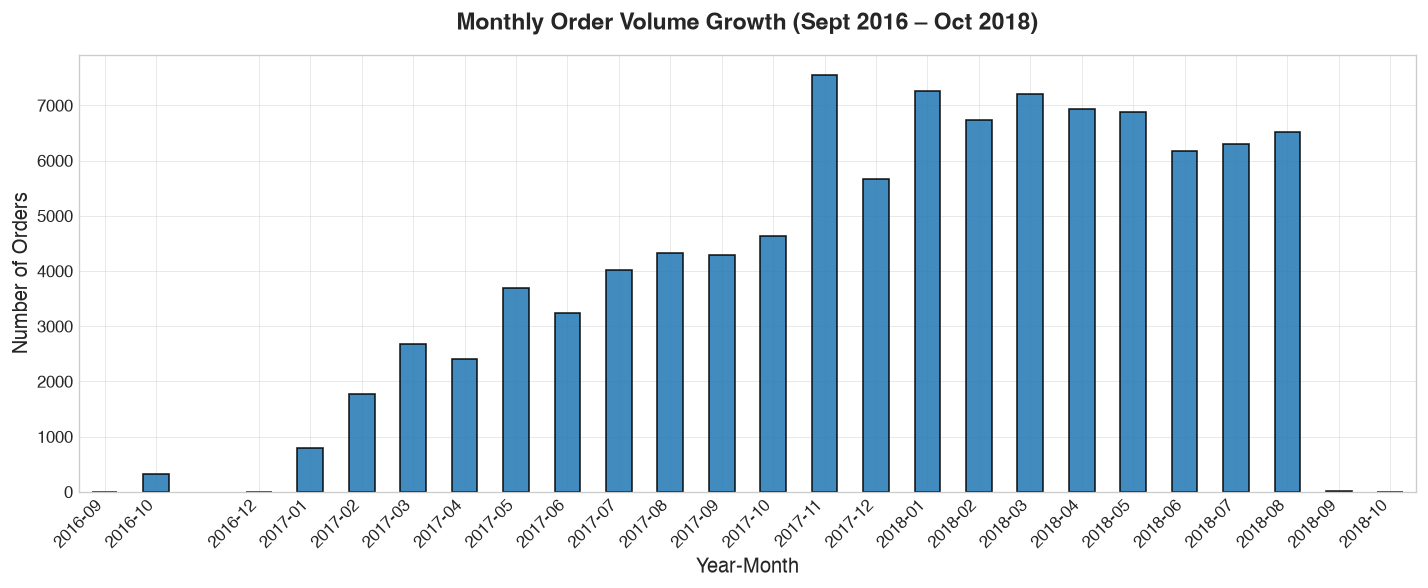

Total recorded orders: 99,441
Date range: 2016-09-04 to 2018-10-17


In [17]:
orders_df = dfs['orders'].copy()
orders_df['order_year_month'] = orders_df['order_purchase_timestamp'].dt.to_period('M')

monthly_orders = orders_df.groupby('order_year_month').size()

plt.figure(figsize=(12, 5))
ax = monthly_orders.plot(kind='bar', color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title('Monthly Order Volume Growth (Sept 2016 – Oct 2018)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Annotate Black Friday 2017 peak
bf_idx = [i for i, x in enumerate(monthly_orders.index) if str(x) == '2017-11'][0]
bf_val = monthly_orders.iloc[bf_idx]
ax.annotate(f'Black Friday 2017\n({bf_val:,} orders)', 
            xy=(bf_idx, bf_val), 
            xytext=(bf_idx - 2, bf_val + 800),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
            fontweight='bold', color='#b22222')

plt.tight_layout()
plt.show()

print(f"Total recorded orders: {len(orders_df):,}")
print(f"Date range: {orders_df['order_purchase_timestamp'].min().strftime('%Y-%m-%d')} to {orders_df['order_purchase_timestamp'].max().strftime('%Y-%m-%d')}")


=== ORDER STATUS DISTRIBUTION ===
              Order Count  Percentage (%)
order_status                             
delivered           96478           97.02
shipped              1107            1.11
canceled              625            0.63
unavailable           609            0.61
invoiced              314            0.32
processing            301            0.30
created                 5            0.01
approved                2            0.00


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/2055084528.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=status_counts.values, y=status_counts.index, palette='Blues_r')


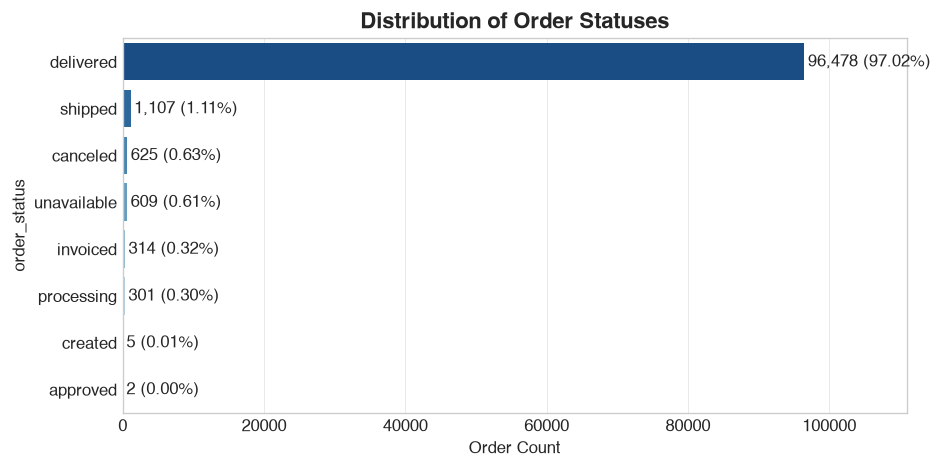

In [18]:
status_counts = orders_df['order_status'].value_counts()
status_pct = orders_df['order_status'].value_counts(normalize=True) * 100

status_summary = pd.DataFrame({
    'Order Count': status_counts,
    'Percentage (%)': status_pct.round(2)
})
print("=== ORDER STATUS DISTRIBUTION ===")
print(status_summary)

plt.figure(figsize=(8, 4))
sns.barplot(x=status_counts.values, y=status_counts.index, palette='Blues_r')
plt.title('Distribution of Order Statuses', fontsize=13, fontweight='bold')
plt.xlabel('Order Count')
for i, v in enumerate(status_counts.values):
    plt.text(v + 500, i, f"{v:,} ({status_pct.iloc[i]:.2f}%)", va='center', fontsize=10)
plt.xlim(0, status_counts.max() * 1.15)
plt.tight_layout()
plt.show()


## 5. Logistics, Fulfillment & Delivery Performance
Delivery duration and reliability are the single most significant drivers of customer retention and satisfaction in e-commerce.
Here we evaluate:
- **Delivery Lead Time**: Elapsed calendar days from purchase to customer receipt.
- **Estimated vs. Actual Variance**: How often are deliveries on-time vs. delayed?
- **Carrier Transit Time**: Time spent in transit with the logistics carrier.


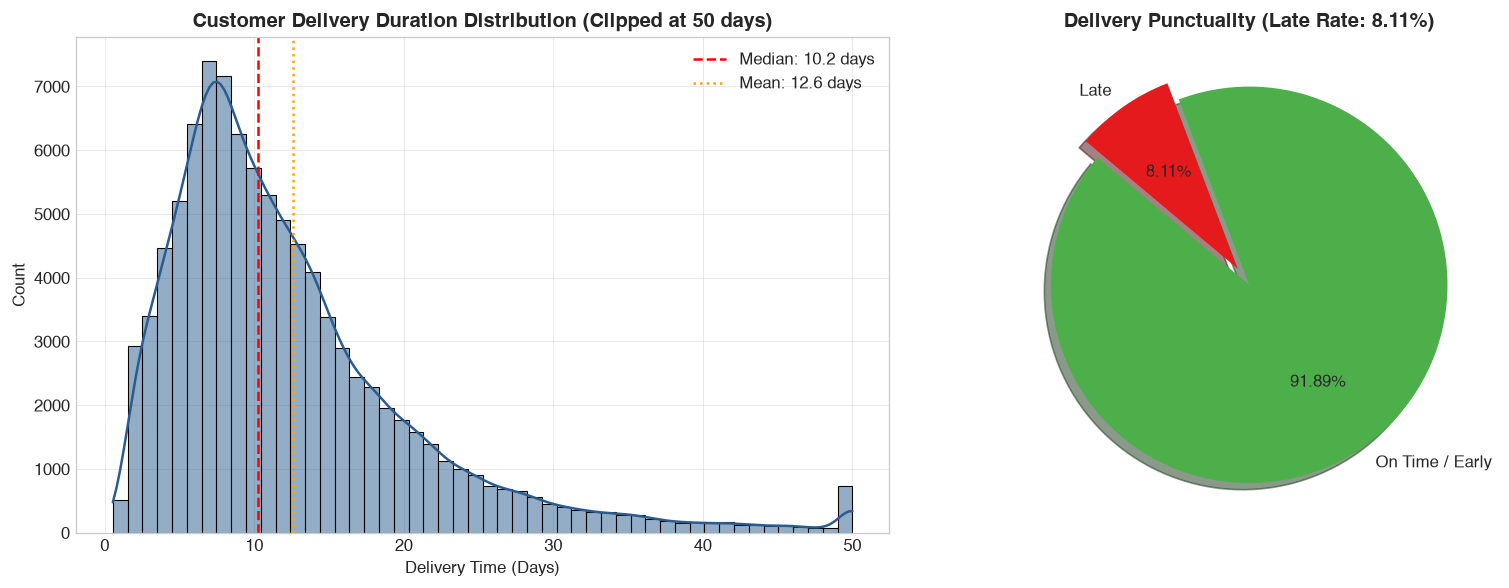

Delivery Metric Statistics (Days):
       total_delivery_days  carrier_transit_days  est_diff_days
count             96470.00              96469.00       96470.00
mean                 12.56                  9.33         -11.18
std                   9.55                  8.76          10.18
min                   0.53                -16.10        -146.02
25%                   6.77                  4.10         -16.24
50%                  10.22                  7.10         -11.95
75%                  15.72                 12.03          -6.39
max                 209.63                205.19         188.98


In [19]:
delivered = orders_df[orders_df['order_status'] == 'delivered'].dropna(
    subset=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
).copy()

# Compute key delivery durations in days
delivered['total_delivery_days'] = (delivered['order_delivered_customer_date'] - delivered['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
delivered['carrier_transit_days'] = (delivered['order_delivered_customer_date'] - delivered['order_delivered_carrier_date']).dt.total_seconds() / (24 * 3600)
delivered['approval_time_hours'] = (delivered['order_approved_at'] - delivered['order_purchase_timestamp']).dt.total_seconds() / 3600
delivered['est_diff_days'] = (delivered['order_delivered_customer_date'] - delivered['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)
delivered['is_late'] = delivered['est_diff_days'] > 0

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of delivery days
sns.histplot(delivered['total_delivery_days'].clip(0, 50), bins=50, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].axvline(delivered['total_delivery_days'].median(), color='red', linestyle='--', label=f"Median: {delivered['total_delivery_days'].median():.1f} days")
axes[0].axvline(delivered['total_delivery_days'].mean(), color='orange', linestyle=':', label=f"Mean: {delivered['total_delivery_days'].mean():.1f} days")
axes[0].set_title('Customer Delivery Duration Distribution (Clipped at 50 days)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Delivery Time (Days)')
axes[0].legend()

# On-time vs Late Pie Chart
late_counts = delivered['is_late'].value_counts()
axes[1].pie(late_counts, labels=['On Time / Early', 'Late'], autopct='%.2f%%', startangle=140, 
            colors=['#4daf4a', '#e41a1c'], explode=(0, 0.1), shadow=True)
axes[1].set_title(f'Delivery Punctuality (Late Rate: {delivered["is_late"].mean()*100:.2f}%)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Delivery Metric Statistics (Days):")
print(delivered[['total_delivery_days', 'carrier_transit_days', 'est_diff_days']].describe().round(2))


## 6. Financial Structure, Payment Methods & Installments
E-commerce in Brazil features unique payment behaviors, heavily utilizing installment credit plans and **Boleto Bancário** (cash voucher slips).


=== PAYMENT METHOD BREAKDOWN ===


,transaction_count,total_gmv,average_ticket,median_ticket,mean_installments,max_installments,gmv_percentage,tx_percentage
payment_type,,,,,,,,
credit_card,76795,12542084.19,163.32,106.87,3.51,24,78.34,73.92
boleto,19784,2869361.27,145.03,93.89,1.00,1,17.92,19.04
voucher,5775,379436.87,65.70,39.28,1.00,1,2.37,5.56
debit_card,1529,217989.79,142.57,89.30,1.00,1,1.36,1.47
not_defined,3,0.00,0.00,0.00,1.00,1,0.00,0.00


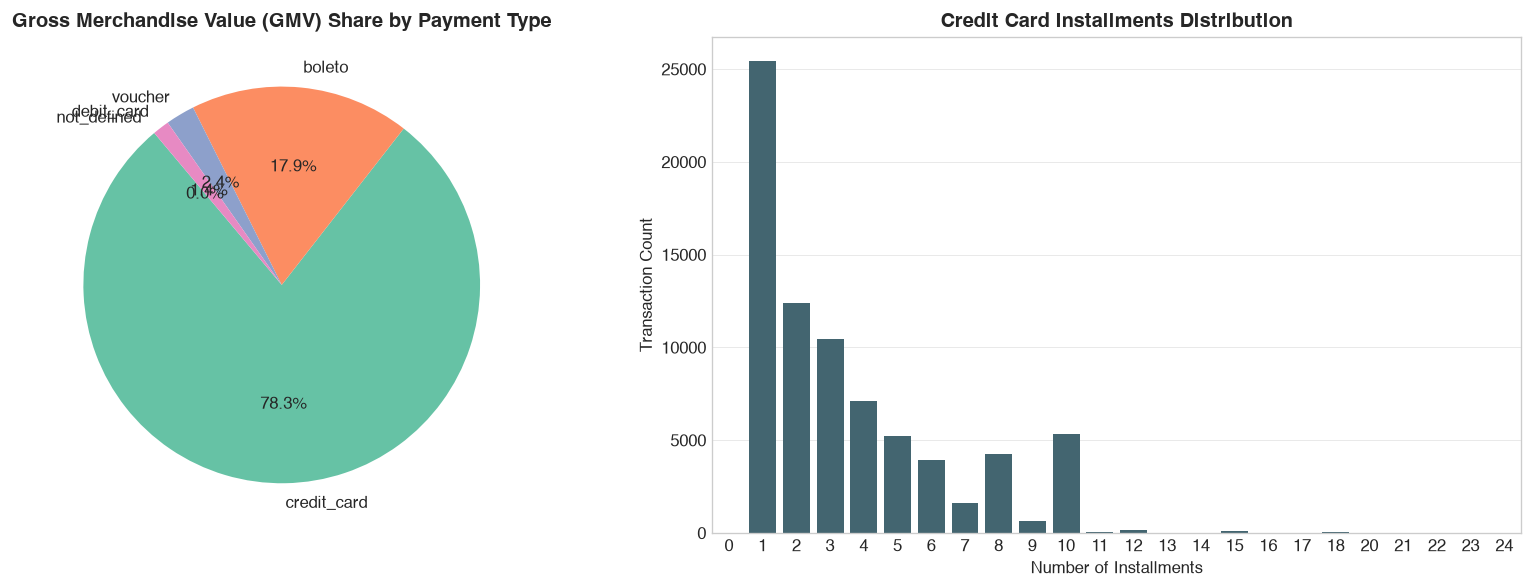

In [20]:
payments_df = dfs['payments'].copy()

payment_metrics = payments_df.groupby('payment_type').agg(
    transaction_count=('payment_value', 'count'),
    total_gmv=('payment_value', 'sum'),
    average_ticket=('payment_value', 'mean'),
    median_ticket=('payment_value', 'median'),
    mean_installments=('payment_installments', 'mean'),
    max_installments=('payment_installments', 'max')
).sort_values(by='total_gmv', ascending=False)

payment_metrics['gmv_percentage'] = (payment_metrics['total_gmv'] / payment_metrics['total_gmv'].sum() * 100).round(2)
payment_metrics['tx_percentage'] = (payment_metrics['transaction_count'] / payment_metrics['transaction_count'].sum() * 100).round(2)

print("=== PAYMENT METHOD BREAKDOWN ===")
display(payment_metrics)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GMV Share by Payment Type
axes[0].pie(payment_metrics['total_gmv'], labels=payment_metrics.index, autopct='%.1f%%',
            colors=sns.color_palette('Set2', len(payment_metrics)), startangle=130)
axes[0].set_title('Gross Merchandise Value (GMV) Share by Payment Type', fontsize=12, fontweight='bold')

# Installment Distribution for Credit Card
credit_card_tx = payments_df[payments_df['payment_type'] == 'credit_card']
sns.countplot(data=credit_card_tx, x='payment_installments', ax=axes[1], color='#3b6978')
axes[1].set_title('Credit Card Installments Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Installments')
axes[1].set_ylabel('Transaction Count')

plt.tight_layout()
plt.show()


## 7. Product Catalog & Category Sales Performance
We map product categories to English translations and analyze:
- Top product categories by total sales volume (items sold).
- Top product categories by Gross Merchandise Value (revenue).
- Freight value sensitivity across categories.


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/802342240.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_revenue['total_revenue'] / 1e6, y=top10_revenue.index, ax=axes[0], palette='viridis')
/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/802342240.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_volume['total_items_sold'], y=top10_volume.index, ax=axes[1], palette='magma')


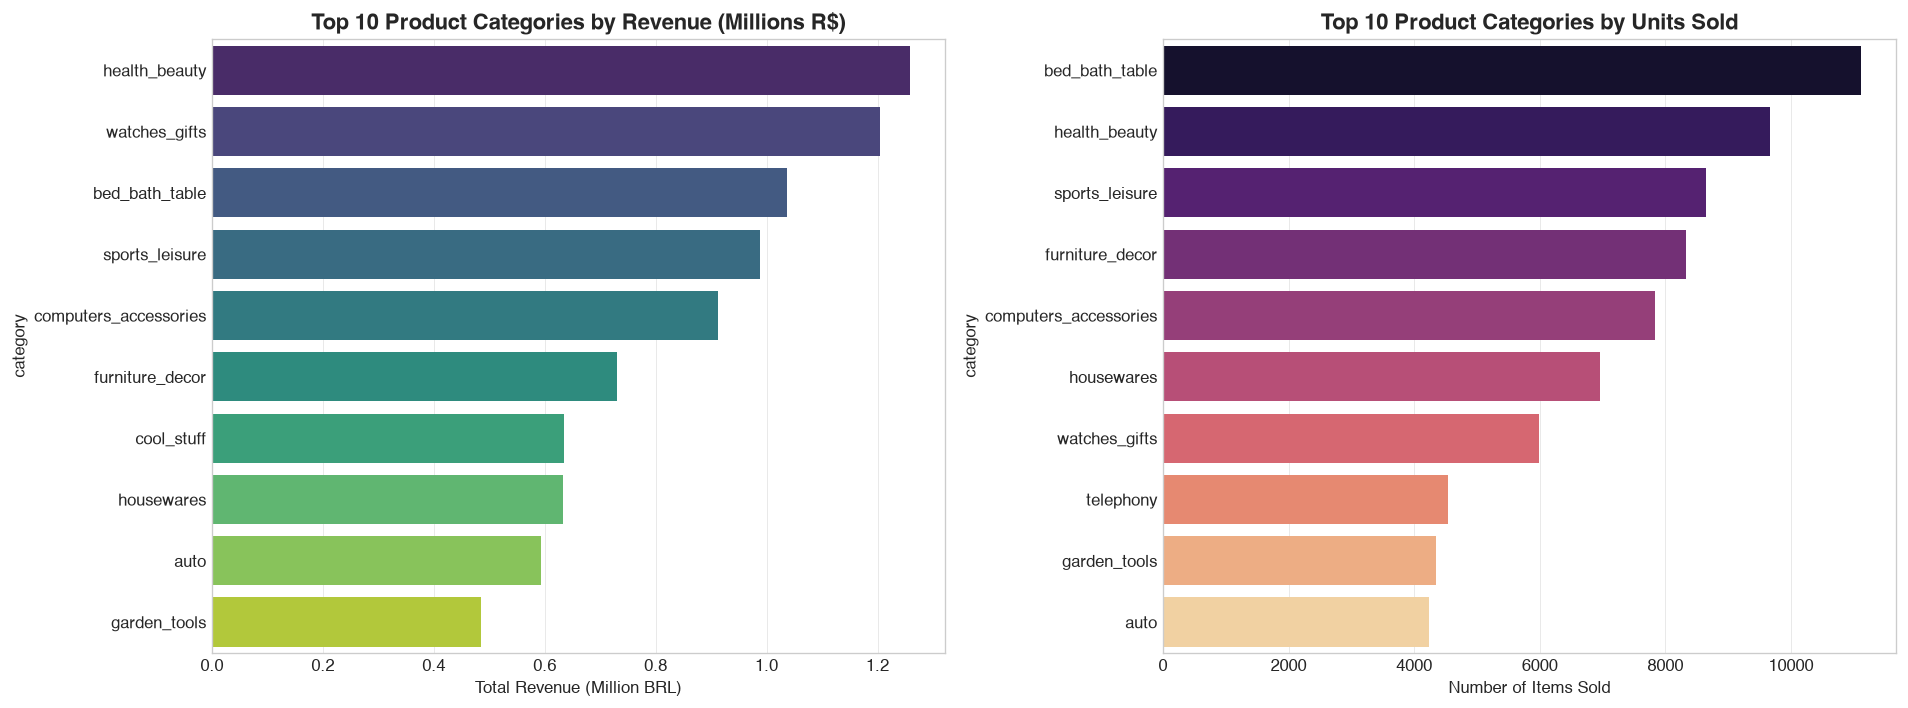

Top 10 Categories Summary:


,total_revenue,total_items_sold,avg_price,avg_freight
category,,,,
health_beauty,1258681.34,9670,130.16,18.88
watches_gifts,1205005.68,5991,201.14,16.78
bed_bath_table,1036988.68,11115,93.30,18.42
sports_leisure,988048.97,8641,114.34,19.51
computers_accessories,911954.32,7827,116.51,18.82
furniture_decor,729762.49,8334,87.56,20.73
cool_stuff,635290.85,3796,167.36,22.14
housewares,632248.66,6964,90.79,20.99
auto,592720.11,4235,139.96,21.88


In [21]:
items_products = dfs['items'].merge(dfs['products'], on='product_id', how='left')
items_products = items_products.merge(dfs['cat_trans'], on='product_category_name', how='left')

# Impute English category name fallback
items_products['category'] = items_products['product_category_name_english'].fillna(
    items_products['product_category_name']
).fillna('Uncategorized')

category_performance = items_products.groupby('category').agg(
    total_items_sold=('order_item_id', 'count'),
    total_revenue=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean')
).sort_values(by='total_revenue', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10_revenue = category_performance.head(10)
top10_volume = category_performance.sort_values(by='total_items_sold', ascending=False).head(10)

sns.barplot(x=top10_revenue['total_revenue'] / 1e6, y=top10_revenue.index, ax=axes[0], palette='viridis')
axes[0].set_title('Top 10 Product Categories by Revenue (Millions R$)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Revenue (Million BRL)')

sns.barplot(x=top10_volume['total_items_sold'], y=top10_volume.index, ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Product Categories by Units Sold', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Items Sold')

plt.tight_layout()
plt.show()

print("Top 10 Categories Summary:")
display(top10_revenue[['total_revenue', 'total_items_sold', 'avg_price', 'avg_freight']].round(2))


## 8. Geographic Distribution & Trade Imbalance
Brazil is a continent-sized nation with deep regional infrastructure disparities.
We assess customer state concentrations vs. seller state concentrations to uncover interstate trade flows.


<Figure size 1680x600 with 0 Axes>

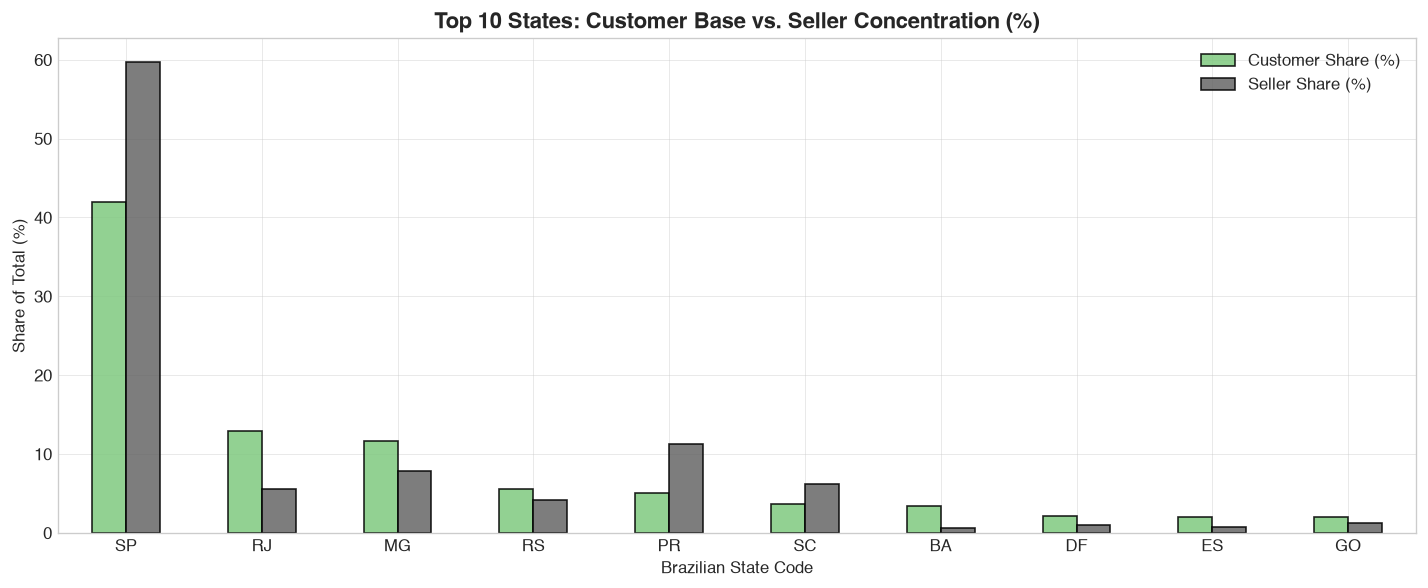

Top 10 Brazilian States by Market Activity:


,Customer Count,Customer Share (%),Seller Count,Seller Share (%)
SP,41746,41.98,1849.00,59.74
RJ,12852,12.92,171.00,5.53
MG,11635,11.70,244.00,7.88
RS,5466,5.50,129.00,4.17
PR,5045,5.07,349.00,11.28
SC,3637,3.66,190.00,6.14
BA,3380,3.40,19.00,0.61
DF,2140,2.15,30.00,0.97
ES,2033,2.04,23.00,0.74
GO,2020,2.03,40.00,1.29


In [22]:
cust_states = dfs['customers']['customer_state'].value_counts()
seller_states = dfs['sellers']['seller_state'].value_counts()

geo_comparison = pd.DataFrame({
    'Customer Count': cust_states,
    'Customer Share (%)': (cust_states / cust_states.sum() * 100).round(2),
    'Seller Count': seller_states,
    'Seller Share (%)': (seller_states / seller_states.sum() * 100).round(2)
}).fillna(0).sort_values(by='Customer Count', ascending=False)

plt.figure(figsize=(14, 5))
state_plot_df = geo_comparison.head(10)[['Customer Share (%)', 'Seller Share (%)']]
state_plot_df.plot(kind='bar', figsize=(12, 5), colormap='Accent', edgecolor='black', alpha=0.85)
plt.title('Top 10 States: Customer Base vs. Seller Concentration (%)', fontsize=13, fontweight='bold')
plt.xlabel('Brazilian State Code')
plt.ylabel('Share of Total (%)')
plt.xticks(rotation=0)
plt.legend(['Customer Share (%)', 'Seller Share (%)'])
plt.tight_layout()
plt.show()

print("Top 10 Brazilian States by Market Activity:")
display(geo_comparison.head(10))


## 9. Customer Satisfaction Drivers & Review Correlation
Customer reviews range from 1 to 5 stars.
Here we evaluate the relationship between customer satisfaction and logistics performance:
Does late delivery directly cause 1-star reviews?


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/3012744169.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=reviews_df, x='review_score', ax=axes[0], palette='Blues_d')
/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_3106/3012744169.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rev_analysis, x='review_score', y='late_order_pct', ax=axes[1], palette='Reds_r')


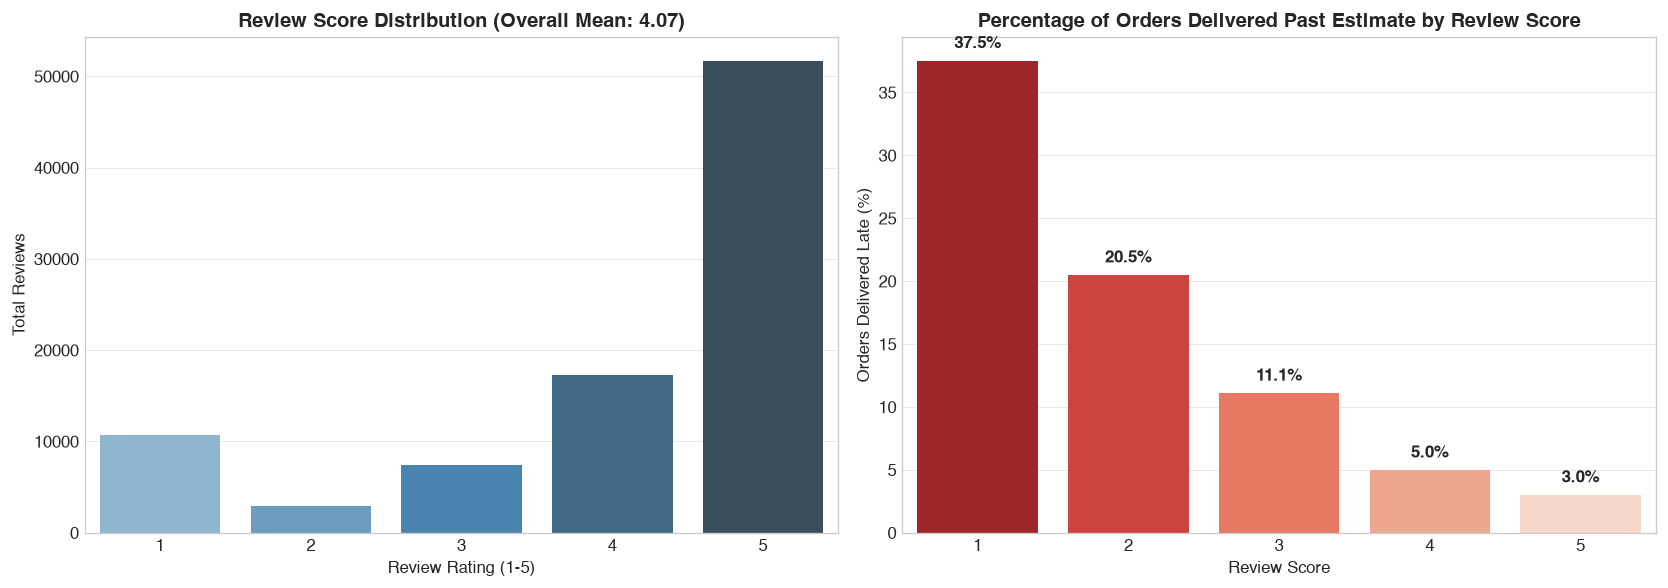

Customer Review vs Logistics Correlation Table:


,review_score,total_reviews,mean_delivery_days,median_delivery_days,late_order_pct
0,1,8793,21.29,16.69,37.53
1,2,2694,16.71,13.27,20.49
2,3,7241,14.30,12.03,11.09
3,4,17135,12.29,10.80,4.98
4,5,51461,10.70,9.24,3.01


In [23]:
reviews_df = dfs['reviews'].copy()

# Join reviews with delivered orders to investigate delivery impact
rev_deliv = reviews_df.merge(
    delivered[['order_id', 'total_delivery_days', 'est_diff_days', 'is_late']],
    on='order_id',
    how='inner'
)

rev_analysis = rev_deliv.groupby('review_score').agg(
    total_reviews=('order_id', 'count'),
    mean_delivery_days=('total_delivery_days', 'mean'),
    median_delivery_days=('total_delivery_days', 'median'),
    late_order_pct=('is_late', lambda x: x.mean() * 100)
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Review score distribution
sns.countplot(data=reviews_df, x='review_score', ax=axes[0], palette='Blues_d')
axes[0].set_title('Review Score Distribution (Overall Mean: {:.2f})'.format(reviews_df['review_score'].mean()), fontsize=12, fontweight='bold')
axes[0].set_xlabel('Review Rating (1-5)')
axes[0].set_ylabel('Total Reviews')

# Late order % by review score
sns.barplot(data=rev_analysis, x='review_score', y='late_order_pct', ax=axes[1], palette='Reds_r')
axes[1].set_title('Percentage of Orders Delivered Past Estimate by Review Score', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Review Score')
axes[1].set_ylabel('Orders Delivered Late (%)')
for i, row in rev_analysis.iterrows():
    axes[1].text(i, row['late_order_pct'] + 1, f"{row['late_order_pct']:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("Customer Review vs Logistics Correlation Table:")
display(rev_analysis.round(2))


## 10. Customer Repeat Purchases & Retention Analysis
A crucial e-commerce health indicator is customer lifetime retention.
We use `customer_unique_id` to evaluate how many customers return to make multiple purchases on Olist.


=== CUSTOMER RETENTION PROFILE ===
Total Unique Customers          96096.00
Single-Order Customers (1x)     93099.00
Single-Order Share (%)             96.88
Repeat Customers (>1x)           2997.00
Repeat Customer Share (%)           3.12
Max Orders by Single Customer      17.00
dtype: float64


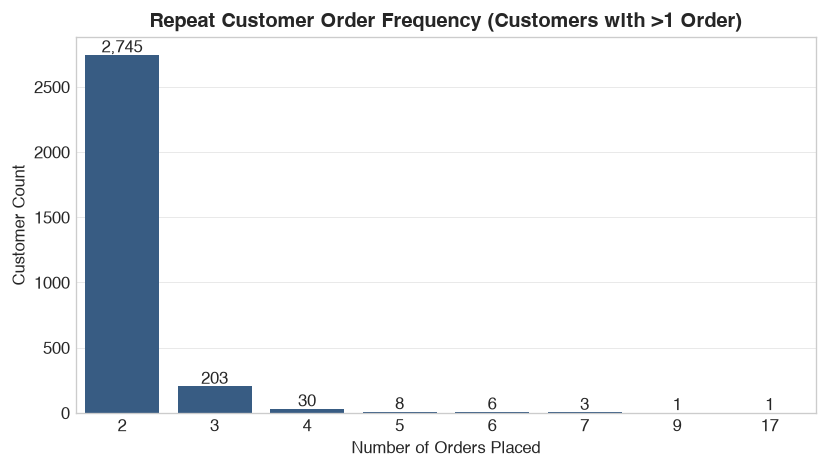

In [24]:
cust_freq = dfs['customers'].groupby('customer_unique_id').size()

retention_summary = pd.Series({
    'Total Unique Customers': len(cust_freq),
    'Single-Order Customers (1x)': (cust_freq == 1).sum(),
    'Single-Order Share (%)': (cust_freq == 1).mean() * 100,
    'Repeat Customers (>1x)': (cust_freq > 1).sum(),
    'Repeat Customer Share (%)': (cust_freq > 1).mean() * 100,
    'Max Orders by Single Customer': cust_freq.max()
})

print("=== CUSTOMER RETENTION PROFILE ===")
print(retention_summary.round(2))

plt.figure(figsize=(7, 4))
repeat_dist = cust_freq[cust_freq > 1].value_counts().sort_index()
sns.barplot(x=repeat_dist.index[:8], y=repeat_dist.values[:8], color='#2b5c8f')
plt.title('Repeat Customer Order Frequency (Customers with >1 Order)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Orders Placed')
plt.ylabel('Customer Count')
for i, v in enumerate(repeat_dist.values[:8]):
    plt.text(i, v + 20, f"{v:,}", ha='center')
plt.tight_layout()
plt.show()


## 11. Key Findings & Strategic Recommendations

### Core Empirical Takeaways
1. **Logistics is the Primary Driver of Churn & Negative Reviews**:
   - 37.5% of 1-star reviews were delivered past the estimated delivery date, with an average delivery duration of 21.3 days (vs. 10.7 days for 5-star reviews).
   - Setting conservative delivery estimates and proactively managing logistics delays can immediately cut low ratings.
2. **Customer Retention is Ultra-Low (3.12%)**:
   - 96.88% of customers made only a single purchase between 2016 and 2018.
   - Olist acts as an acquisition channel rather than a high-retention destination. Introducing loyalty rewards, retargeting campaigns, or post-purchase subscription mechanisms could substantially enhance Customer Lifetime Value (LTV).
3. **Severe Geographic Asymmetry**:
   - Over **59% of sellers** are concentrated in São Paulo (SP), whereas customer demand is distributed across all 27 Brazilian states.
   - Cross-country transit from the Southeast to the North/Northeast incurs steep freight costs and elevated delivery delays.
4. **Dominance of Credit Card Installments & Boleto**:
   - Credit cards represent **78.3% of GMV**, with an average installment count of 3.5 months.
   - Boleto Bancário accounts for **17.9% of GMV**, serving unbanked or credit-averse consumers.
5. **Data Quality Flags**:
   - `portateis_cozinha_e_preparadores_de_alimentos` and `pc_gamer` are missing English translations.
   - 610 products have missing dimensions and category labels.
   - Geolocation coordinates contain ~68 coordinate outliers situated outside Brazil's geographic bounding box.
